In [1]:
%pip install tensorflow numpy matplotlib

^C
Note: you may need to restart the kernel to use updated packages.
   ---------------------------------------- 0.0/384.1 MB ? eta -:--:--
   ---------------------------------------- 0.5/384.1 MB 3.4 MB/s eta 0:01:54
   ---------------------------------------- 1.0/384.1 MB 3.3 MB/s eta 0:01:58
   ---------------------------------------- 1.8/384.1 MB 3.4 MB/s eta 0:01:53
   ---------------------------------------- 2.9/384.1 MB 3.6 MB/s eta 0:01:46
   ---------------------------------------- 3.4/384.1 MB 3.7 MB/s eta 0:01:43
   ---------------------------------------- 4.5/384.1 MB 3.7 MB/s eta 0:01:44
    --------------------------------------- 5.5/384.1 MB 3.9 MB/s eta 0:01:39
    --------------------------------------- 6.3/384.1 MB 3.9 MB/s eta 0:01:37
    --------------------------------------- 7.3/384.1 MB 4.0 MB/s eta 0:01:35
    --------------------------------------- 7.9/384.1 MB 3.8 MB/s eta 0:01:38
    --------------------------------------- 8.4/384.1 MB 3.8 MB/s eta 0:01:40
  

In [2]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

print("TensorFlow version:", tf.__version__)
print("All libraries imported successfully!")

TensorFlow version: 2.22.0-rc0
All libraries imported successfully!


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten (Flatten)                    │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         100,480 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 10)                  │             650 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 7s 12ms/step - accuracy: 0.8827 - loss: 0.3964 - val_accuracy: 0.9622 - val_loss: 0.1378
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.9485 - loss: 0.1744 - val_accuracy: 0.9735 - val_loss: 0.1007
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9606 - loss: 0.1295 - val_accuracy: 0.9757 - val_loss: 0.0872
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.9684 - loss: 0.1057 - val_accuracy: 0.9760 - val_loss: 0.0883
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9732 - loss: 0.0885 - val_accuracy: 0.9783 - val_loss: 0.0781
Test Loss: 0.0799
Test Accuracy: 97.45%

Sample Predictions:
Image 1: Actual = 7, Predicted = 7
Image 2: Actual = 2, Predicted = 2
Image 3: Actual = 1, Predicted = 1
Image 4: Actual = 0, Predicted = 0
Image 5: Actual = 4, Predicted = 4
Image 6: Actual = 1, Predicted = 1
Image 7: Actual = 4, Predicted = 4
Image 8: Actual = 9, Predicted = 9
Image 9: Actual = 5, Pr

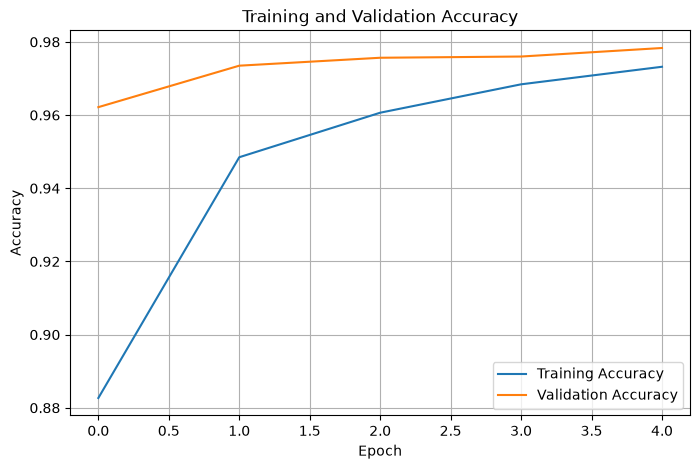

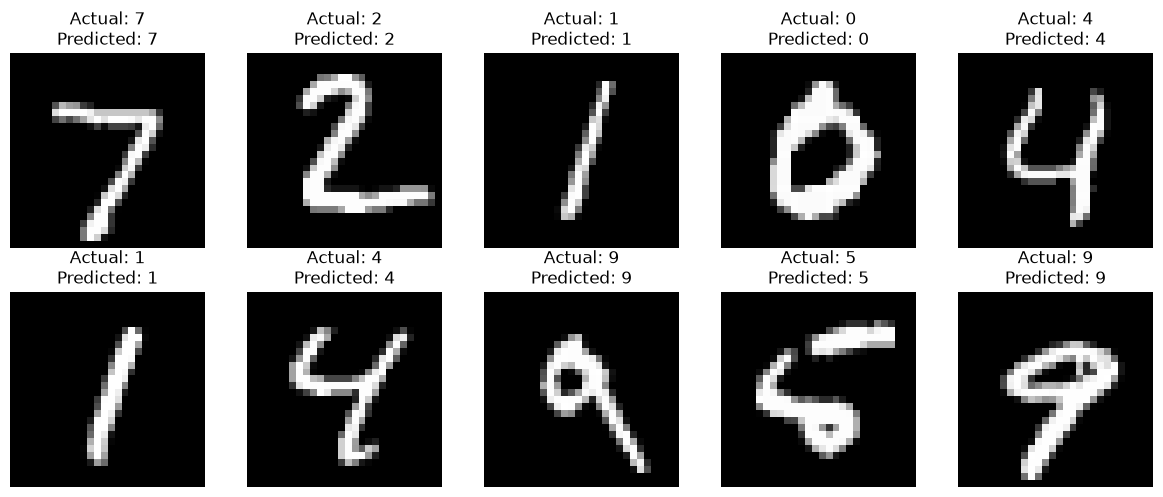

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Flatten, Dense, Dropout

# Load MNIST dataset
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

# Normalize image pixels
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Create Deep Neural Network
model = Sequential([
    Input(shape=(28, 28)),
    Flatten(),
    Dense(128, activation="relu"),
    Dropout(0.2),
    Dense(64, activation="relu"),
    Dense(10, activation="softmax")
])

# Compile the model
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Display model structure
model.summary()

# Train the model
history = model.fit(
    x_train,
    y_train,
    epochs=5,
    batch_size=128,
    validation_split=0.1,
    verbose=1
)

# Evaluate model performance
test_loss, test_accuracy = model.evaluate(
    x_test, y_test, verbose=0
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

# Predict digits
predictions = model.predict(x_test[:10], verbose=0)
predicted_labels = np.argmax(predictions, axis=1)

print("\nSample Predictions:")
for i in range(10):
    print(
        f"Image {i + 1}: Actual = {y_test[i]}, "
        f"Predicted = {predicted_labels[i]}"
    )

# Plot training and validation accuracy
plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

# Display predicted digit images
plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[i], cmap="gray")
    plt.title(
        f"Actual: {y_test[i]}\nPredicted: {predicted_labels[i]}"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

In [4]:
%pip install gymnasium numpy matplotlib

Note: you may need to restart the kernel to use updated packages.


Training completed!
Goal reached successfully!
Path: [(0, 0), (0, 1), (0, 2), (1, 2), (2, 2), (2, 3), (2, 4), (3, 4), (4, 4)]
Number of moves: 8


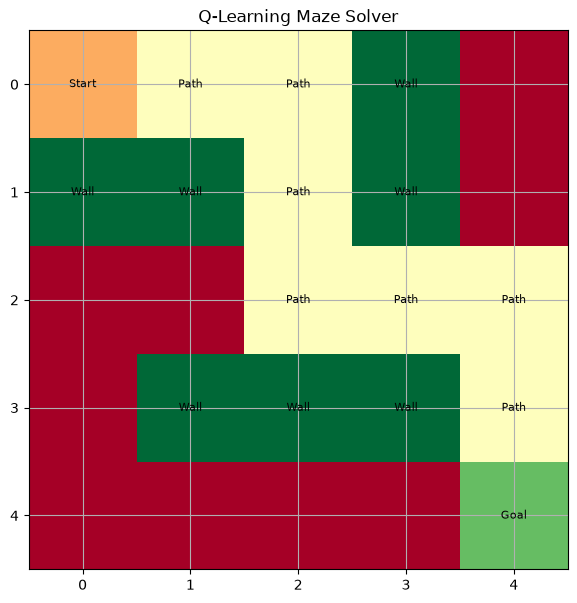

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import random

# Create the maze
maze = np.array([
    [0, 0, 0, 1, 0],
    [1, 1, 0, 1, 0],
    [0, 0, 0, 0, 0],
    [0, 1, 1, 1, 0],
    [0, 0, 0, 0, 0]
])

rows, cols = maze.shape
start = (0, 0)
goal = (4, 4)

# Define actions: up, down, left, right
actions = [(-1, 0), (1, 0), (0, -1), (0, 1)]

# Initialize Q-table
q_table = np.zeros((rows * cols, len(actions)))

# Hyperparameters
learning_rate = 0.8
discount_factor = 0.95
epsilon = 0.2
episodes = 3000
max_steps = 100

def state_to_index(state):
    return state[0] * cols + state[1]

def take_action(state, action_index):
    dr, dc = actions[action_index]
    new_row = state[0] + dr
    new_col = state[1] + dc

    if (0 <= new_row < rows and
        0 <= new_col < cols and
        maze[new_row, new_col] == 0):
        return (new_row, new_col)

    return state

# Q-Learning training
for episode in range(episodes):
    state = start

    for step in range(max_steps):
        state_index = state_to_index(state)

        if random.random() < epsilon:
            action_index = random.randint(0, 3)
        else:
            action_index = np.argmax(q_table[state_index])

        next_state = take_action(state, action_index)
        next_index = state_to_index(next_state)

        if next_state == goal:
            reward = 100
        elif next_state == state:
            reward = -5
        else:
            reward = -1

        old_value = q_table[state_index, action_index]

        if next_state == goal:
            next_max = 0
        else:
            next_max = np.max(q_table[next_index])

        q_table[state_index, action_index] = (
            old_value + learning_rate *
            (reward + discount_factor * next_max - old_value)
        )

        state = next_state

        if state == goal:
            break

print("Training completed!")

# Find the learned path
state = start
path = [state]
visited = {state}

for step in range(rows * cols):
    if state == goal:
        break

    state_index = state_to_index(state)
    action_index = np.argmax(q_table[state_index])
    next_state = take_action(state, action_index)

    if next_state == state or next_state in visited:
        print("Could not find a complete path.")
        break

    state = next_state
    path.append(state)
    visited.add(state)

# Display results
if path[-1] == goal:
    print("Goal reached successfully!")
    print("Path:", path)
    print("Number of moves:", len(path) - 1)

# Visualize maze and path
display_maze = maze.astype(float).copy()

for r, c in path:
    display_maze[r, c] = 0.5

display_maze[start] = 0.3
display_maze[goal] = 0.8

plt.figure(figsize=(7, 7))
plt.imshow(display_maze, cmap="RdYlGn", vmin=0, vmax=1)

for r in range(rows):
    for c in range(cols):
        if maze[r, c] == 1:
            label = "Wall"
        elif (r, c) == start:
            label = "Start"
        elif (r, c) == goal:
            label = "Goal"
        elif (r, c) in path:
            label = "Path"
        else:
            label = ""

        if label:
            plt.text(c, r, label, ha="center", va="center", fontsize=8)

plt.xticks(range(cols))
plt.yticks(range(rows))
plt.title("Q-Learning Maze Solver")
plt.grid(True)
plt.show()